   unique_brands  unique_tones
0            330            10
   oldest_campaign  newest_campaign
0             2015             2024


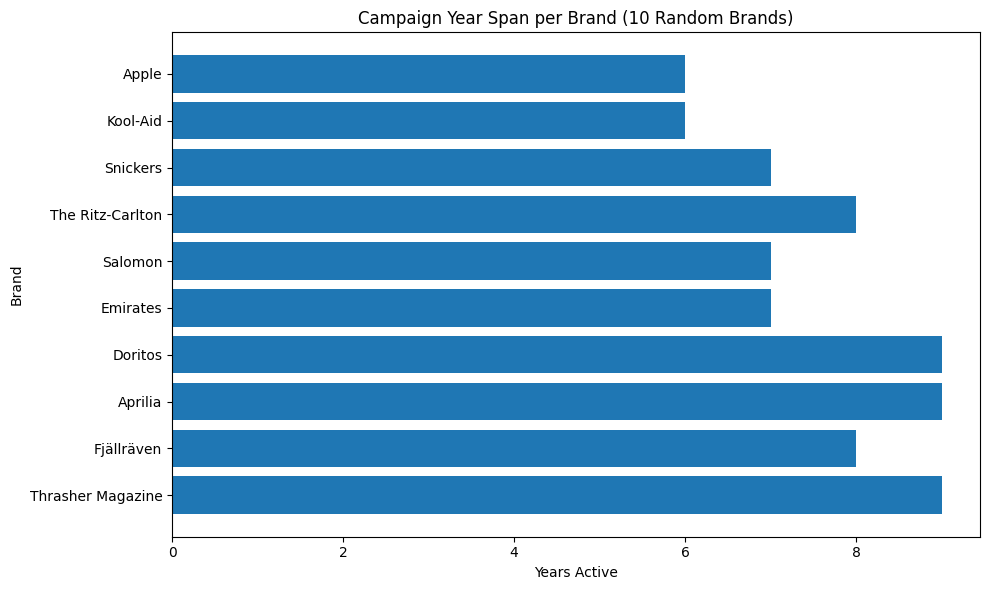

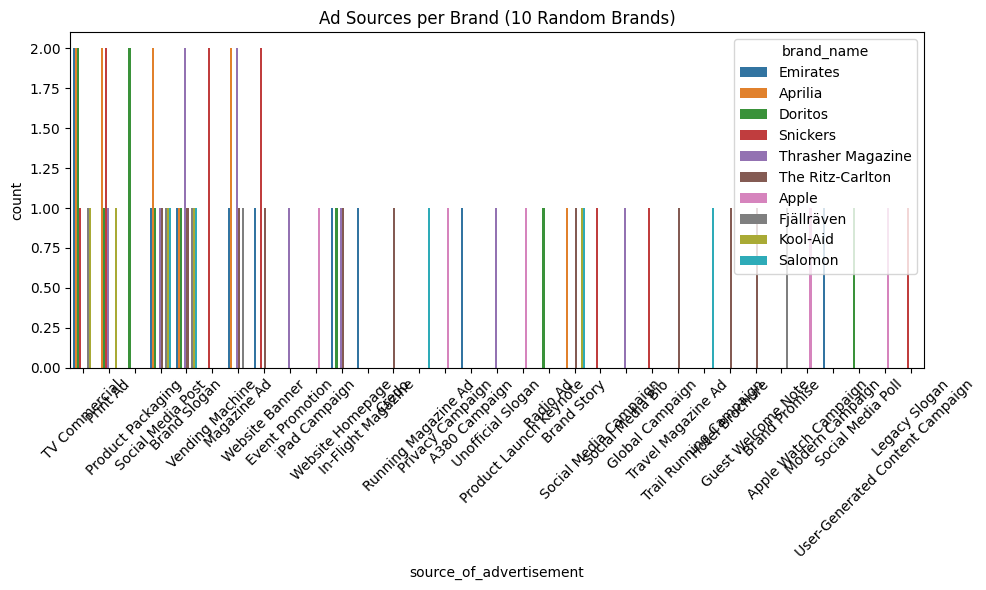

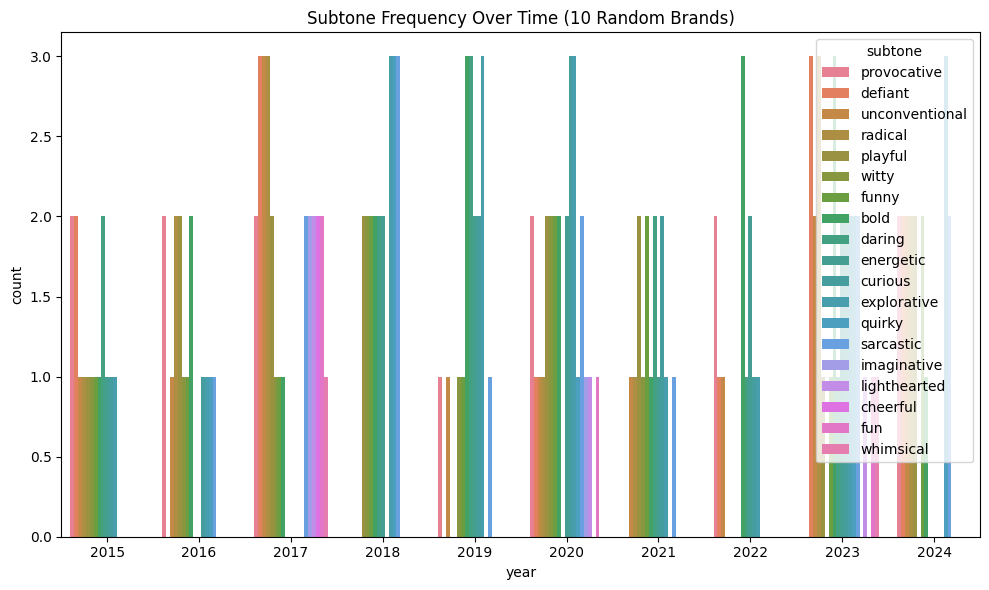

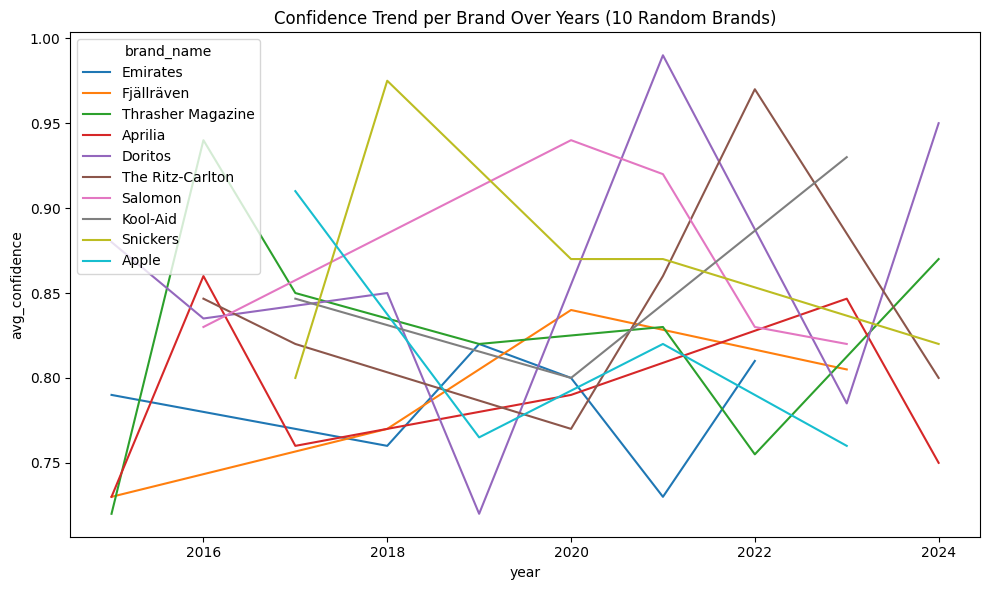

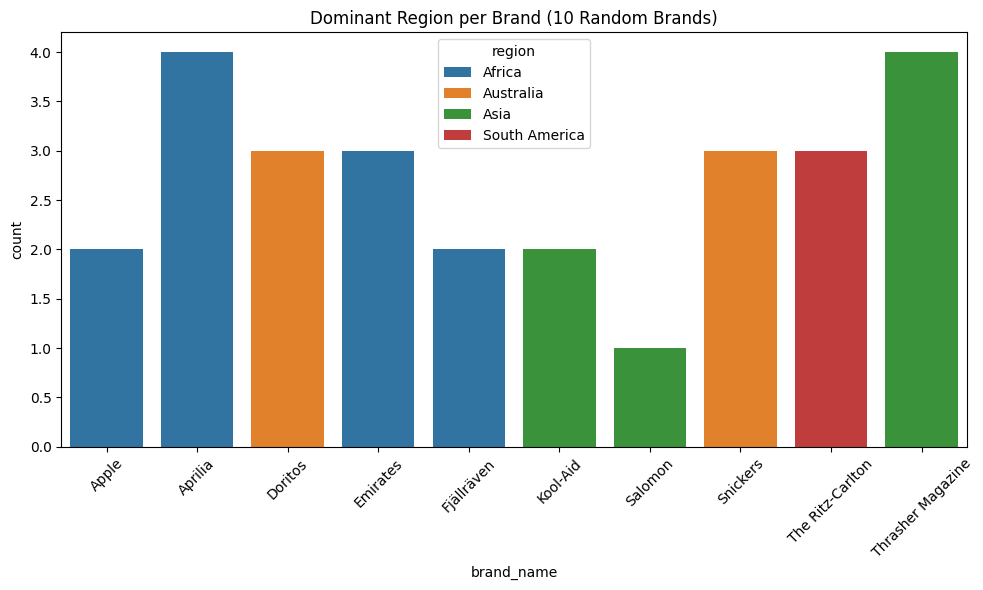

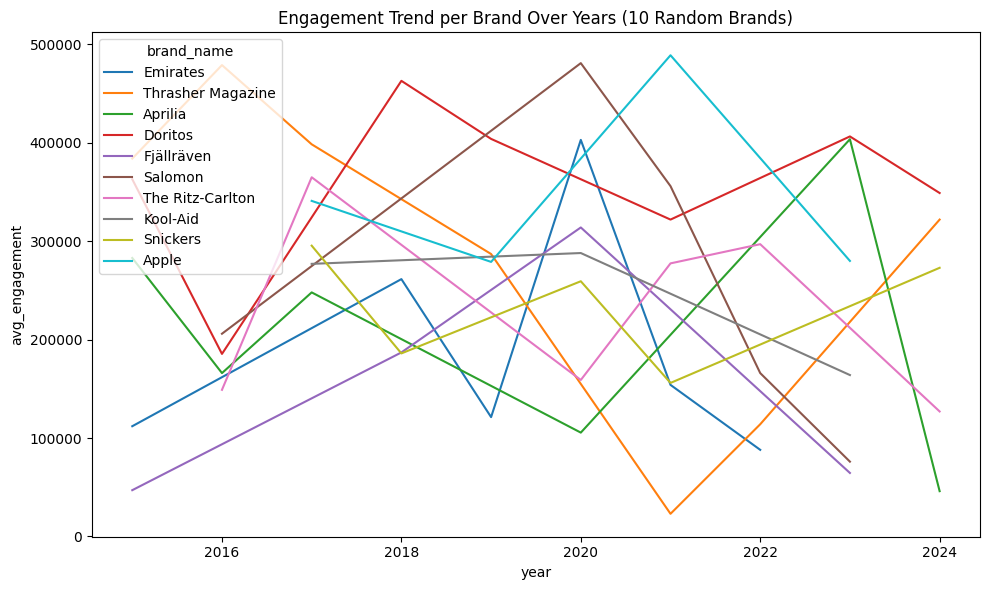

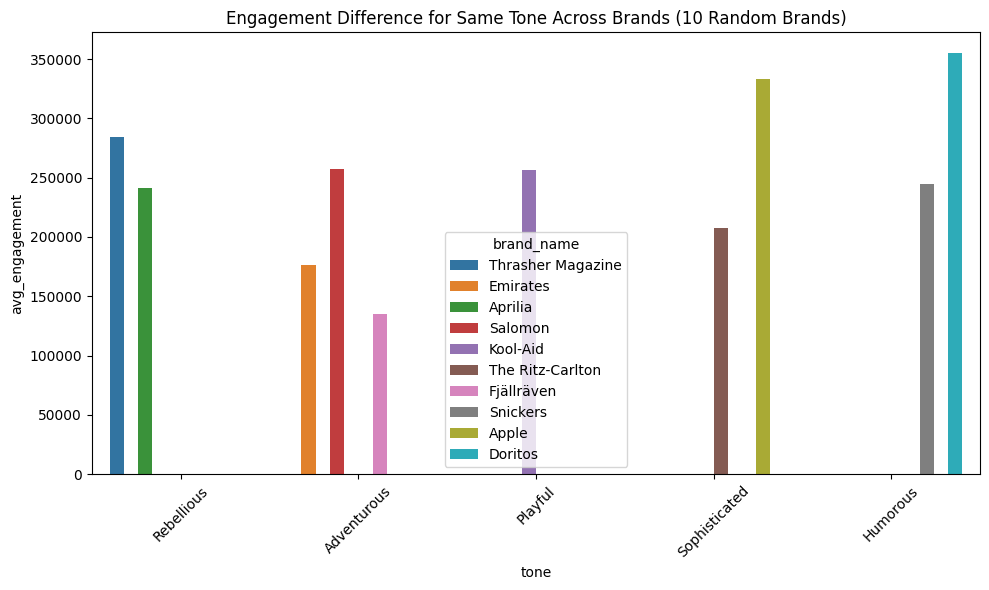

In [29]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import ast

# ---------------------------------------------------
# 1️⃣ Load dataset directly into DuckDB
# ---------------------------------------------------
csv_path = "enhanced_tone_dataset.csv"
con = duckdb.connect()
df = con.execute(f"SELECT * FROM '{csv_path}'").df()

# Convert engagement (e.g., '230K') to numeric
def convert_engagement(val):
    if isinstance(val, str):
        val = val.strip().upper()
        if val.endswith("K"):
            return float(val[:-1]) * 1e3
        elif val.endswith("M"):
            return float(val[:-1]) * 1e6
    try:
        return float(val)
    except:
        return 0.0

df["engagement_num"] = df["engagement_metric"].apply(convert_engagement)

# Register DataFrame as table for SQL
con.register("tones", df)

# ---------------------------------------------------
# 2️⃣ Unique brands and tones
# ---------------------------------------------------
unique_counts = con.execute("""
SELECT COUNT(DISTINCT brand_name) AS unique_brands,
       COUNT(DISTINCT tone) AS unique_tones
FROM tones
""").df()
print(unique_counts)

# ---------------------------------------------------
# 3️⃣ Year range per brand & overall
# ---------------------------------------------------
year_range = con.execute("""
SELECT brand_name,
       MIN(year_of_campaign_start) AS oldest_year,
       MAX(year_of_campaign_start) AS newest_year
FROM tones
GROUP BY brand_name
ORDER BY oldest_year
""").df()

overall_years = con.execute("""
SELECT MIN(year_of_campaign_start) AS oldest_campaign,
       MAX(year_of_campaign_start) AS newest_campaign
FROM tones
""").df()
print(overall_years)

# Select 10 random brands for plotting
sample_brands = np.random.choice(year_range["brand_name"], size=10, replace=False)
year_range_sample = year_range[year_range["brand_name"].isin(sample_brands)]

# Plot – campaign span
plt.figure(figsize=(10,6))
plt.barh(year_range_sample["brand_name"], year_range_sample["newest_year"] - year_range_sample["oldest_year"])
plt.title("Campaign Year Span per Brand (10 Random Brands)")
plt.xlabel("Years Active")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()

# ---------------------------------------------------
# 4️⃣ Ad sources per brand
# ---------------------------------------------------
sources = con.execute("""
SELECT brand_name, source_of_advertisement, COUNT(*) AS count
FROM tones
GROUP BY brand_name, source_of_advertisement
ORDER BY count DESC
""").df()

sources_sample = sources[sources["brand_name"].isin(sample_brands)]

plt.figure(figsize=(10,6))
sns.barplot(data=sources_sample, x="source_of_advertisement", y="count", hue="brand_name")
plt.title("Ad Sources per Brand (10 Random Brands)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ---------------------------------------------------
# 5️⃣ Subtone change over time
# ---------------------------------------------------
df["sub_tones"] = df["sub_tones"].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) and x.startswith("[") else [])
subtone_rows = []
for _, row in df.iterrows():
    if row["brand_name"] in sample_brands:
        for s in row["sub_tones"]:
            subtone_rows.append((row["brand_name"], row["year_of_campaign_start"], s))
subtone_df = pd.DataFrame(subtone_rows, columns=["brand_name", "year", "subtone"])

plt.figure(figsize=(10,6))
sns.countplot(data=subtone_df, x="year", hue="subtone")
plt.title("Subtone Frequency Over Time (10 Random Brands)")
plt.tight_layout()
plt.show()

# ---------------------------------------------------
# 6️⃣ Confidence trend over years per brand
# ---------------------------------------------------
conf_trend = con.execute("""
SELECT brand_name, year_of_campaign_start AS year,
       AVG(confidence_score) AS avg_confidence
FROM tones
WHERE brand_name IN ({})
GROUP BY brand_name, year_of_campaign_start
ORDER BY year
""".format(",".join(f"'{b}'" for b in sample_brands))).df()

plt.figure(figsize=(10,6))
sns.lineplot(data=conf_trend, x="year", y="avg_confidence", hue="brand_name")
plt.title("Confidence Trend per Brand Over Years (10 Random Brands)")
plt.tight_layout()
plt.show()

# ---------------------------------------------------
# 7️⃣ Dominant region for each brand
# ---------------------------------------------------
region_dom = con.execute("""
SELECT brand_name, region, COUNT(*) AS count
FROM tones
WHERE brand_name IN ({})
GROUP BY brand_name, region
""".format(",".join(f"'{b}'" for b in sample_brands))).df()

region_top = region_dom.sort_values(["brand_name","count"], ascending=[True,False]).groupby("brand_name").head(1)

plt.figure(figsize=(10,6))
sns.barplot(data=region_top, x="brand_name", y="count", hue="region")
plt.title("Dominant Region per Brand (10 Random Brands)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ---------------------------------------------------
# 8️⃣ Engagement trend per brand over years
# ---------------------------------------------------
engagement_trend = con.execute("""
SELECT brand_name, year_of_campaign_start AS year,
       AVG(engagement_num) AS avg_engagement,
       AVG(confidence_score) AS avg_confidence
FROM tones
WHERE brand_name IN ({})
GROUP BY brand_name, year_of_campaign_start
ORDER BY year
""".format(",".join(f"'{b}'" for b in sample_brands))).df()

plt.figure(figsize=(10,6))
sns.lineplot(data=engagement_trend, x="year", y="avg_engagement", hue="brand_name")
plt.title("Engagement Trend per Brand Over Years (10 Random Brands)")
plt.tight_layout()
plt.show()

# ---------------------------------------------------
# 9️⃣ Engagement difference between brands sharing same tone
# ---------------------------------------------------
same_tone = con.execute("""
SELECT tone, brand_name, AVG(engagement_num) AS avg_engagement
FROM tones
WHERE brand_name IN ({})
GROUP BY tone, brand_name
""".format(",".join(f"'{b}'" for b in sample_brands))).df()

plt.figure(figsize=(10,6))
sns.barplot(data=same_tone, x="tone", y="avg_engagement", hue="brand_name")
plt.title("Engagement Difference for Same Tone Across Brands (10 Random Brands)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
